In [10]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
# =========================
# Configuration
# =========================
RESULT_DIR = Path("../results/pca_sign")   # Change this to your result directory

SIGN_MAP = {
    "0": 0,
    "p1": 1,
    "m1": -1,
}

SIGN_LABELS = {
    0: "Dynamic",
    1: "+PCA",
    -1: "-PCA",
}

In [12]:
# =========================
# Filename parser
# =========================

def parse_std_weighted_filename(path: Path):
    """
    Expected filename format:

        {aggregator}_std_weighted_k{topk}_{sign}.csv

    Examples:
        fedavg_std_weighted_k2_0.csv
        fedavg_std_weighted_k2_p1.csv
        fedavg_std_weighted_k3_m1.csv
    """

    name = path.stem

    match = re.fullmatch(
        r"(.+)_std_weighted_k(\d+)_(0|p1|m1)",
        name
    )

    if match is None:
        return None

    aggregator, top_k, sign_str = match.groups()

    return {
        "aggregator": aggregator,
        "top_k": int(top_k),
        "sign": SIGN_MAP[sign_str],
        "sign_str": sign_str,
    }

In [13]:
test_files = [
    Path("fedavg_std_weighted_k2_0.csv"),
    Path("fedavg_std_weighted_k2_p1.csv"),
    Path("fedavg_std_weighted_k3_m1.csv"),
]

for f in test_files:
    print(parse_std_weighted_filename(f))

{'aggregator': 'fedavg', 'top_k': 2, 'sign': 0, 'sign_str': '0'}
{'aggregator': 'fedavg', 'top_k': 2, 'sign': 1, 'sign_str': 'p1'}
{'aggregator': 'fedavg', 'top_k': 3, 'sign': -1, 'sign_str': 'm1'}


In [14]:
# =========================
# CSV loader
# =========================

def load_result_csv(path: Path):
    df = pd.read_csv(path)

    required_columns = [
        "round",
        "test_accuracy",
    ]

    for col in required_columns:
        if col not in df.columns:
            raise ValueError(
                f"{path.name} is missing required column: {col}"
            )

    # Convert possible object/string columns into numeric values.
    # Invalid footer rows such as #### become NaN.
    df["round"] = pd.to_numeric(
        df["round"],
        errors="coerce",
    )

    df["test_accuracy"] = pd.to_numeric(
        df["test_accuracy"],
        errors="coerce",
    )

    # Optional columns
    optional_numeric_columns = [
        "test_loss",
        "global_update_norm",
        "gamma",
        "malicious_clients",
        "aggregated_malicious_clients",
    ]

    for col in optional_numeric_columns:
        if col in df.columns:
            df[col] = pd.to_numeric(
                df[col],
                errors="coerce",
            )

    # Remove malformed rows
    df = df.dropna(
        subset=["round", "test_accuracy"]
    )

    df = df.sort_values("round").reset_index(drop=True)

    return df

In [15]:
# =========================
# Load all STD-weighted runs
# =========================

def load_std_weighted_experiments(result_dir: Path):
    experiments = []

    for path in result_dir.glob("*.csv"):

        config = parse_std_weighted_filename(path)

        if config is None:
            continue

        try:
            df = load_result_csv(path)

        except Exception as e:
            print(f"Failed to load {path.name}: {e}")
            continue

        experiments.append({
            **config,
            "path": path,
            "data": df,
        })

    return experiments

In [16]:
print("RESULT_DIR =", RESULT_DIR)
print("Absolute path =", RESULT_DIR.resolve())
print("Exists =", RESULT_DIR.exists())

print("\nFiles found:")
for path in RESULT_DIR.glob("*"):
    print(path.name)

RESULT_DIR = ../results/pca_sign
Absolute path = /Users/bill/Documents/Research/adaptiveFL/results/pca_sign
Exists = True

Files found:
fedavg_pc2_p1.csv
fedavg_pc3_0.csv
fedavg_pc3_m1.csv
prodigy_std_weighted_k2_0.csv
median_pc1_m1.csv
trimmed_mean_pc2_0.csv
fedavg_pc1_0.csv
prodigy_pc1_p1.csv
multikrum_pc3_0.csv
median_pc3_m1.csv
multikrum_std_weighted_k2_p1.csv
fedavg_pc1_m1.csv
krum_pc1_0.csv
prodigy_pc3_p1.csv
multikrum_std_weighted_k3_0.csv
prodigy_pc2_m1.csv
krum_pc3_0.csv
median_pc2_p1.csv
multikrum_std_weighted_k3_m1.csv
multikrum_pc1_0.csv
trimmed_mean_pc3_0.csv
krum_pc2_m1.csv
prodigy_std_weighted_k3_0.csv
multikrum_pc2_p1.csv
median_std_weighted_k3_m1.csv
trimmed_mean_pc1_m1.csv
median_std_weighted_k2_p1.csv
multikrum_pc3_m1.csv
fedavg_pc2_0.csv
trimmed_mean_pc1_0.csv
krum_pc3_p1.csv
fedavg_std_weighted_k3_p1.csv
krum_pc2_0.csv
prodigy_std_weighted_k2_m1.csv
multikrum_std_weighted_k2_0.csv
trimmed_mean_pc3_m1.csv
krum_std_weighted_k2_p1.csv
multikrum_pc1_m1.csv
krum_pc1_p1.

In [17]:
experiments = load_std_weighted_experiments(
    RESULT_DIR
)

print(f"Loaded {len(experiments)} experiments")

for exp in experiments:
    print(
        exp["aggregator"],
        f"k={exp['top_k']}",
        f"sign={exp['sign']}",
        exp["path"].name,
    )

Loaded 36 experiments
prodigy k=2 sign=0 prodigy_std_weighted_k2_0.csv
multikrum k=2 sign=1 multikrum_std_weighted_k2_p1.csv
multikrum k=3 sign=0 multikrum_std_weighted_k3_0.csv
multikrum k=3 sign=-1 multikrum_std_weighted_k3_m1.csv
prodigy k=3 sign=0 prodigy_std_weighted_k3_0.csv
median k=3 sign=-1 median_std_weighted_k3_m1.csv
median k=2 sign=1 median_std_weighted_k2_p1.csv
fedavg k=3 sign=1 fedavg_std_weighted_k3_p1.csv
prodigy k=2 sign=-1 prodigy_std_weighted_k2_m1.csv
multikrum k=2 sign=0 multikrum_std_weighted_k2_0.csv
krum k=2 sign=1 krum_std_weighted_k2_p1.csv
trimmed_mean k=3 sign=1 trimmed_mean_std_weighted_k3_p1.csv
trimmed_mean k=2 sign=-1 trimmed_mean_std_weighted_k2_m1.csv
fedavg k=2 sign=-1 fedavg_std_weighted_k2_m1.csv
prodigy k=3 sign=1 prodigy_std_weighted_k3_p1.csv
krum k=3 sign=-1 krum_std_weighted_k3_m1.csv
trimmed_mean k=2 sign=0 trimmed_mean_std_weighted_k2_0.csv
krum k=3 sign=0 krum_std_weighted_k3_0.csv
median k=3 sign=0 median_std_weighted_k3_0.csv
multikrum k

In [18]:
# =========================
# Metrics
# =========================

def compute_metrics(df: pd.DataFrame, last_n: int = 5):
    if df.empty:
        return {
            "final_acc": np.nan,
            "last_n_acc": np.nan,
            "mean_acc": np.nan,
            "normalized_auc": np.nan,
            "min_acc": np.nan,
            "max_acc": np.nan,
        }

    final_acc = df["test_accuracy"].iloc[-1]

    last_n_acc = (
        df["test_accuracy"]
        .tail(last_n)
        .mean()
    )

    mean_acc = df["test_accuracy"].mean()

    min_acc = df["test_accuracy"].min()
    max_acc = df["test_accuracy"].max()

    if len(df) >= 2:
        x = df["round"].to_numpy()
        y = df["test_accuracy"].to_numpy()

        auc = np.trapezoid(y, x)

        duration = x[-1] - x[0]

        if duration > 0:
            normalized_auc = auc / duration
        else:
            normalized_auc = np.nan

    else:
        normalized_auc = np.nan

    return {
        "final_acc": final_acc,
        "last_n_acc": last_n_acc,
        "mean_acc": mean_acc,
        "normalized_auc": normalized_auc,
        "min_acc": min_acc,
        "max_acc": max_acc,
    }

In [19]:
# =========================
# Build summary table
# =========================

def build_summary(
    experiments,
    last_n: int = 5,
):
    rows = []

    for exp in experiments:
        metrics = compute_metrics(
            exp["data"],
            last_n=last_n,
        )

        rows.append({
            "aggregator": exp["aggregator"],
            "top_k": exp["top_k"],
            "sign": exp["sign"],
            "sign_label": SIGN_LABELS[exp["sign"]],
            **metrics,
            "file": exp["path"].name,
        })

    return pd.DataFrame(rows)

In [20]:
summary = build_summary(
    experiments,
    last_n=5,
)

summary

,aggregator,top_k,sign,sign_label,final_acc,last_n_acc,mean_acc,normalized_auc,min_acc,max_acc,file
0,prodigy,2,0,Dynamic,0.7594,0.74810,0.597819,0.606620,0.0842,0.8351,prodigy_std_weighted_k2_0.csv
1,multikrum,2,1,+PCA,0.7696,0.81848,0.608519,0.617600,0.0842,0.8459,multikrum_std_weighted_k2_p1.csv
2,multikrum,3,0,Dynamic,0.8699,0.86294,0.648676,0.657258,0.0842,0.8911,multikrum_std_weighted_k3_0.csv
3,multikrum,3,-1,-PCA,0.8632,0.88042,0.620510,0.627850,0.0842,0.9043,multikrum_std_weighted_k3_m1.csv
4,prodigy,3,0,Dynamic,0.7015,0.72586,0.535862,0.543013,0.0842,0.8543,prodigy_std_weighted_k3_0.csv
5,median,3,-1,-PCA,0.8852,0.88254,0.629181,0.636405,0.0842,0.9124,median_std_weighted_k3_m1.csv
6,median,2,1,+PCA,0.7935,0.83374,0.625390,0.634718,0.0842,0.8527,median_std_weighted_k2_p1.csv
7,fedavg,3,1,+PCA,0.8697,0.85832,0.593824,0.599668,0.0842,0.8697,fedavg_std_weighted_k3_p1.csv
8,prodigy,2,-1,-PCA,0.7711,0.65478,0.514814,0.519172,0.0842,0.8550,prodigy_std_weighted_k2_m1.csv
9,multikrum,2,0,Dynamic,0.8674,0.84842,0.620276,0.627500,0.0842,0.8794,multikrum_std_weighted_k2_0.csv


In [21]:
# =========================
# Overall ranking
# Lower accuracy = stronger attack
# =========================

ranking = summary.sort_values(
    [
        "aggregator",
        "last_n_acc",
        "normalized_auc",
    ],
    ascending=True,
).reset_index(drop=True)

ranking

,aggregator,top_k,sign,sign_label,final_acc,last_n_acc,mean_acc,normalized_auc,min_acc,max_acc,file
0,fedavg,2,1,+PCA,0.7519,0.81896,0.614167,0.623973,0.0842,0.8500,fedavg_std_weighted_k2_p1.csv
1,fedavg,2,-1,-PCA,0.9071,0.83430,0.594400,0.599337,0.0842,0.9071,fedavg_std_weighted_k2_m1.csv
2,fedavg,3,1,+PCA,0.8697,0.85832,0.593824,0.599668,0.0842,0.8697,fedavg_std_weighted_k3_p1.csv
3,fedavg,3,-1,-PCA,0.8832,0.87250,0.618443,0.625180,0.0842,0.8846,fedavg_std_weighted_k3_m1.csv
4,fedavg,2,0,Dynamic,0.9261,0.87720,0.604019,0.608962,0.0842,0.9261,fedavg_std_weighted_k2_0.csv
5,fedavg,3,0,Dynamic,0.8211,0.89126,0.620781,0.629187,0.0842,0.9234,fedavg_std_weighted_k3_0.csv
6,krum,3,0,Dynamic,0.7740,0.76576,0.589619,0.597645,0.0842,0.8011,krum_std_weighted_k3_0.csv
7,krum,3,1,+PCA,0.7108,0.77632,0.594700,0.604560,0.0842,0.8417,krum_std_weighted_k3_p1.csv
8,krum,2,1,+PCA,0.7387,0.79102,0.601343,0.610837,0.0842,0.8388,krum_std_weighted_k2_p1.csv
9,krum,2,0,Dynamic,0.8171,0.83480,0.629024,0.637943,0.0842,0.8496,krum_std_weighted_k2_0.csv


In [22]:
# =========================
# Best config per aggregator
# =========================

best_per_aggregator = (
    summary
    .sort_values(
        [
            "last_n_acc",
            "normalized_auc",
        ]
    )
    .groupby(
        "aggregator",
        as_index=False,
    )
    .first()
)

best_per_aggregator

,aggregator,top_k,sign,sign_label,final_acc,last_n_acc,mean_acc,normalized_auc,min_acc,max_acc,file
0,fedavg,2,1,+PCA,0.7519,0.81896,0.614167,0.623973,0.0842,0.8500,fedavg_std_weighted_k2_p1.csv
1,krum,3,0,Dynamic,0.7740,0.76576,0.589619,0.597645,0.0842,0.8011,krum_std_weighted_k3_0.csv
2,median,3,1,+PCA,0.8532,0.80328,0.610133,0.617205,0.0842,0.8532,median_std_weighted_k3_p1.csv
3,multikrum,3,1,+PCA,0.8329,0.80142,0.601414,0.608558,0.0842,0.8602,multikrum_std_weighted_k3_p1.csv
4,prodigy,2,-1,-PCA,0.7711,0.65478,0.514814,0.519172,0.0842,0.8550,prodigy_std_weighted_k2_m1.csv
5,trimmed_mean,3,1,+PCA,0.8567,0.82562,0.642500,0.651102,0.0842,0.8974,trimmed_mean_std_weighted_k3_p1.csv


In [23]:
# =========================
# Plot all STD-weighted configurations
# for one aggregator
# =========================

def plot_std_weighted_accuracy(
    experiments,
    aggregator,
):
    selected = [
        exp
        for exp in experiments
        if exp["aggregator"] == aggregator
    ]

    if len(selected) == 0:
        print(
            f"No experiments found for aggregator={aggregator}"
        )
        return

    plt.figure(figsize=(11, 7))

    selected = sorted(
        selected,
        key=lambda x: (
            x["top_k"],
            x["sign"],
        )
    )

    for exp in selected:
        df = exp["data"]

        label = (
            f"k={exp['top_k']}, "
            f"{SIGN_LABELS[exp['sign']]}"
        )

        plt.plot(
            df["round"],
            df["test_accuracy"],
            marker="o",
            markersize=4,
            linewidth=1.8,
            label=label,
        )

    plt.xlabel("Round")
    plt.ylabel("Test Accuracy")

    plt.title(
        f"STD-Weighted PCA Attack - {aggregator}"
    )

    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.show()

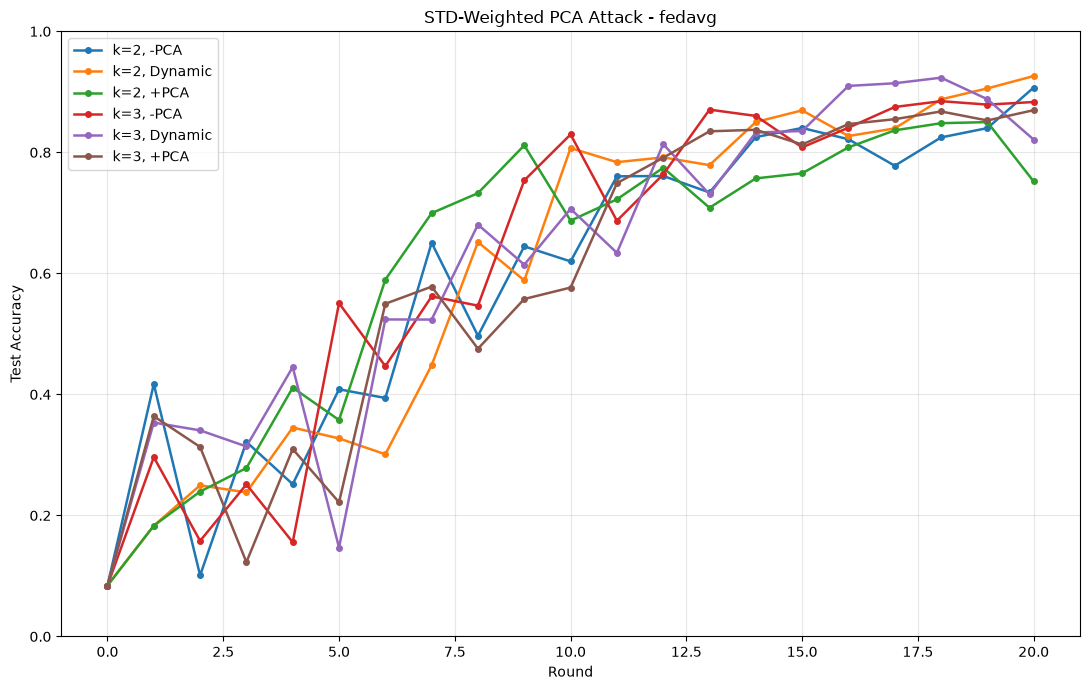

In [24]:
plot_std_weighted_accuracy(
    experiments,
    aggregator="fedavg",
)

In [25]:
# =========================
# Compact ranking
# =========================

compact_ranking = (
    summary[
        [
            "aggregator",
            "top_k",
            "sign_label",
            "final_acc",
            "last_n_acc",
            "normalized_auc",
        ]
    ]
    .sort_values(
        [
            "aggregator",
            "last_n_acc",
        ]
    )
    .reset_index(drop=True)
)

compact_ranking

,aggregator,top_k,sign_label,final_acc,last_n_acc,normalized_auc
0,fedavg,2,+PCA,0.7519,0.81896,0.623973
1,fedavg,2,-PCA,0.9071,0.83430,0.599337
2,fedavg,3,+PCA,0.8697,0.85832,0.599668
3,fedavg,3,-PCA,0.8832,0.87250,0.625180
4,fedavg,2,Dynamic,0.9261,0.87720,0.608962
5,fedavg,3,Dynamic,0.8211,0.89126,0.629187
6,krum,3,Dynamic,0.7740,0.76576,0.597645
7,krum,3,+PCA,0.7108,0.77632,0.604560
8,krum,2,+PCA,0.7387,0.79102,0.610837
9,krum,2,Dynamic,0.8171,0.83480,0.637943


In [26]:
# =========================
# Print winners
# =========================

for aggregator in sorted(
    summary["aggregator"].unique()
):
    sub = summary[
        summary["aggregator"] == aggregator
    ]

    best = sub.sort_values(
        [
            "last_n_acc",
            "normalized_auc",
        ]
    ).iloc[0]

    print(
        f"{aggregator}: "
        f"best = top-{int(best['top_k'])}, "
        f"sign={best['sign_label']}, "
        f"last5={best['last_n_acc']:.4f}, "
        f"AUC={best['normalized_auc']:.4f}"
    )

fedavg: best = top-2, sign=+PCA, last5=0.8190, AUC=0.6240
krum: best = top-3, sign=Dynamic, last5=0.7658, AUC=0.5976
median: best = top-3, sign=+PCA, last5=0.8033, AUC=0.6172
multikrum: best = top-3, sign=+PCA, last5=0.8014, AUC=0.6086
prodigy: best = top-2, sign=-PCA, last5=0.6548, AUC=0.5192
trimmed_mean: best = top-3, sign=+PCA, last5=0.8256, AUC=0.6511


In [29]:
sign_summary = (
    summary
    .groupby(["top_k", "sign"])
    ["last_n_acc"]
    .mean()
    .reset_index()
    .sort_values("last_n_acc")
)

print(sign_summary)

   top_k  sign  last_n_acc
5      3     1    0.808063
0      2    -1    0.818123
2      2     1    0.822093
4      3     0    0.830373
1      2     0    0.840560
3      3    -1    0.866307
